# Phase 4: Frequency Model: Poisson GLM

**Business question this phase serves:** *what is the expected claim count per policy, as a function
of risk factors?* This is the first of the two building blocks of the technical premium
(frequency x severity, Phase 7): a Poisson GLM is the actuarial industry standard starting point for
modeling claim counts, and everything from here on gets compared back to it.

**Inputs:** [`data/processed/train.parquet`](../data/processed/train.parquet),
[`val.parquet`](../data/processed/val.parquet) and
[`models/feature_encoder.joblib`](../models/feature_encoder.joblib), all built in
[Phase 3](03_data_preparation_and_split.ipynb).

**What this notebook does:**
1. Fit the full Poisson GLM: every Phase 3 factor, `log(Exposure)` as an offset.
2. **A coherence check the task explicitly calls for:** confirm every coefficient's *sign* makes sense
   against the univariate evidence from Phase 2, and when one doesn't, explain exactly why, instead
   of reporting it silently.
3. Factor-level backward stepwise selection, and what "statistically significant" does and does not
   mean with 400,000 policies.
4. Read the final model's relativities the way an underwriter would.
5. Validate the model **on the untouched validation set** (Phase 3): actual-vs-predicted by decile,
   residual diagnostics.
6. Save the fitted model and write a model card.

**Memory note for re-runs:** this machine has ~8GB RAM, and a single
Poisson GLM fit on ~401k rows takes real memory (statsmodels keeps the whole design matrix alive
inside the fitted result). `src/models/frequency_glm.py`'s stepwise selection is written to only ever
keep two fitted models in memory at once (see its docstring) for this reason.

## 0. Setup

In [1]:
import sys
import gc
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm


def find_project_root(marker: str = "requirements.txt") -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / marker).exists():
            return candidate
    raise FileNotFoundError(f"Could not locate project root (looked for '{marker}' upward from {here})")

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.features.pipeline import get_frequency_target, get_exposure_offset
from src.models.frequency_glm import (
    fit_poisson_glm,
    build_factor_groups,
    backward_stepwise_selection,
    relativities_table,
)
from src.models.glm_diagnostics import (
    deviance_summary,
    likelihood_ratio_test,
    actual_vs_predicted_by_decile,
    plot_actual_vs_predicted,
    pearson_residuals,
    plot_residuals_vs_fitted,
)

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

train_df = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "train.parquet")
val_df = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "val.parquet")
encoder = joblib.load(PROJECT_ROOT / "models" / "feature_encoder.joblib")

X_train = encoder.transform(train_df)
y_train = get_frequency_target(train_df)
offset_train = get_exposure_offset(train_df)

X_val = encoder.transform(val_df)
y_val = get_frequency_target(val_df)
offset_val = get_exposure_offset(val_df)

print(f"Train: {X_train.shape}, Validation: {X_val.shape}")
print(f"Features: {list(X_train.columns)}")

Train: (401175, 37), Validation: (133725, 37)
Features: ['DrivAge', 'BonusMalus', 'VehPower', 'log_Density', 'VehAge_capped', 'VehBrand_B10', 'VehBrand_B11', 'VehBrand_B12', 'VehBrand_B13', 'VehBrand_B14', 'VehBrand_B2', 'VehBrand_B3', 'VehBrand_B4', 'VehBrand_B5', 'VehBrand_B6', 'VehGas_Regular', 'Region_R21', 'Region_R22', 'Region_R23', 'Region_R24', 'Region_R25', 'Region_R26', 'Region_R31', 'Region_R41', 'Region_R42', 'Region_R43', 'Region_R52', 'Region_R53', 'Region_R54', 'Region_R72', 'Region_R73', 'Region_R74', 'Region_R82', 'Region_R83', 'Region_R91', 'Region_R93', 'Region_R94']


## 1. The model: Poisson GLM with a log(Exposure) offset

$$\log(E[\text{ClaimNb}]) = \log(\text{Exposure}) + \beta_0 + \beta_1 x_1 + \dots + \beta_p x_p$$

Rearranged: $E[\text{ClaimNb}] / \text{Exposure} = \exp(\beta_0 + \beta_1 x_1 + \dots)$: the model
predicts a **rate per policy-year**, with `log(Exposure)`'s coefficient fixed at exactly 1 rather than
estimated (that's what `offset=` does in `statsmodels`). Fitting the full model first: every factor
Phase 3 prepared, nothing dropped yet: gives the baseline everything else in this notebook is judged
against.

In [2]:
full_results = fit_poisson_glm(X_train, y_train, offset_train)
full_summary = deviance_summary(full_results)
for k, v in full_summary.items():
    print(f"{k:<22}: {v:,.4f}" if isinstance(v, float) else f"{k:<22}: {v:,}")

n_obs                 : 401,175
df_model              : 37
df_resid              : 401,137
log_likelihood        : -63,976.9843
deviance              : 97,825.9444
null_deviance         : 101,962.6713
aic                   : 128,029.9685
pseudo_r2_deviance    : 0.0406


**Reading:** the pseudo-R² (deviance-based) is **4.1%**. That is normal for a motor frequency model:
claim occurrence has a large random component (Phase 2: even `BonusMalus`, the strongest single factor,
takes frequency from 5% to 61%, not to 100%). The useful question is whether the model ranks risk
correctly, answered in Section 5 with the actual-vs-predicted decile chart on data the model never saw.

## 2. Coherence check: does `DrivAge`'s sign make sense?

Before trusting any coefficient, check it against the evidence Phase 2 already built. Phase 2 found a
sharp pattern: frequency falls from 19.3% (age 18-22) to about 7% by the 30s. A GLM coefficient for
`DrivAge` should, at minimum, point the same direction.

In [3]:
print("DrivAge coefficient in the FULL multivariate model:")
print(f"  {full_results.params['DrivAge']:+.5f}   (p = {full_results.pvalues['DrivAge']:.2e})")

DrivAge coefficient in the FULL multivariate model:


  +0.00575   (p = 1.45e-21)


**This is positive**: the multivariate model says frequency rises slightly with age, the opposite
direction from the univariate pattern in Phase 2. The next cell tests the most likely explanation:
Phase 2 Section 4 flagged that `DrivAge` and `BonusMalus` are correlated (r = -0.48), since young
drivers have not had time to earn a low `BonusMalus`. Once `BonusMalus` is in the model, part of
`DrivAge`'s apparent effect may really be `BonusMalus`'s.

In [4]:
# DrivAge on its own: no other factors to compete with.
r_age_alone = fit_poisson_glm(X_train[["DrivAge"]], y_train, offset_train)
print(f"DrivAge ALONE               : {r_age_alone.params['DrivAge']:+.5f}  (p = {r_age_alone.pvalues['DrivAge']:.2e})")

# DrivAge together with BonusMalus.
r_age_bm = fit_poisson_glm(X_train[["DrivAge", "BonusMalus"]], y_train, offset_train)
print(f"DrivAge WITH BonusMalus      : {r_age_bm.params['DrivAge']:+.5f}  (p = {r_age_bm.pvalues['DrivAge']:.2e})")
print(f"  (BonusMalus coefficient here: {r_age_bm.params['BonusMalus']:+.5f})")

del r_age_alone, r_age_bm
gc.collect()

DrivAge ALONE               : -0.00997  (p = 3.00e-68)


DrivAge WITH BonusMalus      : +0.00498  (p = 3.99e-17)
  (BonusMalus coefficient here: +0.02609)


92

**Confirmed.** Fitted alone, `DrivAge`'s coefficient is **negative** (-0.00997), matching Phase 2.
As soon as `BonusMalus` enters the model, it **turns positive** (+0.00498). This is confounding:
`BonusMalus` already captures much of the young-driver effect (young drivers structurally carry
higher `BonusMalus` values), and the *remaining* age effect, once `BonusMalus` is controlled for, is
slightly positive over most of the age range.

The multivariate coefficient is the one to use for pricing ("holding everything else fixed"), but it
should not be described as "age increases risk" without this context. A single **linear** coefficient
also cannot represent the actual `DrivAge` shape (a sharp drop for the youngest drivers, then roughly
flat), which is the motivation for a GAM smooth term on `DrivAge` in Phase 5.

## 3. Factor-level backward stepwise selection

Method (`src/models/frequency_glm.py`): eliminate whole rating factors (not individual one-hot
columns) one at a time with a likelihood-ratio test, until every remaining factor is significant at the
5% level. `VehBrand`'s 10 dummies and `Region`'s 21 dummies are each treated as one factor.

**Compute note:** the search fits up to 9 Poisson GLMs in a row. On this 8GB-RAM machine, repeated
fits on the full training set ran out of memory, so the *search* runs on a stratified 25% sub-sample of
the training set (stratified by claim-count bucket, like the Phase 3 split), and its decision is then
checked against the full-data model from Section 1.

In [5]:
from sklearn.model_selection import train_test_split

claim_bucket_train = pd.cut(y_train, bins=[-1, 0, 1, np.inf], labels=["0", "1", "2+"])
X_search, _, y_search, _, offset_search, _ = train_test_split(
    X_train, y_train, offset_train, train_size=0.25, stratify=claim_bucket_train, random_state=42
)
print(f"Search sub-sample: {len(X_search):,} policies ({len(X_search) / len(X_train):.1%} of train)")
print(f"Claim rate: full train: {(y_train > 0).mean():.4%}  |  sub-sample: {(y_search > 0).mean():.4%}")

feature_groups = build_factor_groups(list(X_train.columns))
print("\nCandidate factors:", {name: len(cols) for name, cols in feature_groups.items()})

# Note: `full_results` (Section 1) is deliberately kept alive here rather than deleted: the search
# below only fits models on the 25% sub-sample, so it can run alongside the one full-data model
# already in memory.
_, remaining_groups, history = backward_stepwise_selection(
    X_search, y_search, offset_search, feature_groups, p_threshold=0.05, verbose=True
)
del X_search, y_search, offset_search, claim_bucket_train
gc.collect()

print(f"\nFactors kept on the sub-sample: {list(remaining_groups.keys())}")
print(history)

Search sub-sample: 100,293 policies (25.0% of train)
Claim rate: full train: 3.6902%  |  sub-sample: 3.6902%

Candidate factors: {'DrivAge': 1, 'BonusMalus': 1, 'VehPower': 1, 'Density': 1, 'VehAge': 1, 'VehBrand': 10, 'VehGas': 1, 'Region': 21}



Factors kept on the sub-sample: ['DrivAge', 'BonusMalus', 'VehPower', 'Density', 'VehAge', 'VehBrand', 'VehGas', 'Region']
Empty DataFrame
Columns: []
Index: []


**Finding: the sub-sample search keeps all eight factors.** No factor is dropped, even at a quarter
of the training data.

In [6]:
# Check the sub-sample's decision against what we already know from the FULL data (Section 1) --
# no new model fit needed, `full_results` is the model fitted on all training rows.
print("Full-data significance of the two factors the sub-sample wanted to drop:")
for factor in ["VehGas_Regular", "VehPower"]:
    print(f"  {factor:<16}: p = {full_results.pvalues[factor]:.2e}  (full training data, n={len(X_train):,})")

Full-data significance of the two factors the sub-sample wanted to drop:
  VehGas_Regular  : p = 6.35e-20  (full training data, n=401,175)
  VehPower        : p = 2.08e-15  (full training data, n=401,175)


**The full data confirms it.** On the complete training set, `VehGas` and `VehPower`, the two
factors with the smallest margins, are both clearly significant (p-values above). **All 8 factors are
kept**, and `full_results` (Section 1) is the model carried forward.

In [7]:
# `full_results` (Section 1, all 8 factors, fit on the full training set) is the model
# this notebook carries forward: no further re-fit needed.
final_results = full_results
final_cols = list(X_train.columns)
print(f"Final model: {len(final_cols)} feature columns, fit on the full {len(X_train):,}-row training set.")

Final model: 37 feature columns, fit on the full 401,175-row training set.


## 4. Reading the model: relativities

In [8]:
relativities = relativities_table(final_results)
print("Top 10 relativities (highest predicted frequency, relative to baseline):")
display(relativities[["coefficient", "p_value", "relativity", "relativity_ci_low", "relativity_ci_high"]].head(10))

print("\nBottom 10 relativities (lowest predicted frequency, relative to baseline):")
display(relativities[["coefficient", "p_value", "relativity", "relativity_ci_low", "relativity_ci_high"]].tail(10))

Top 10 relativities (highest predicted frequency, relative to baseline):


,coefficient,p_value,relativity,relativity_ci_low,relativity_ci_high
Region_R74,0.2917,0.0039,1.3387,1.0979,1.6323
Region_R94,0.2473,0.0281,1.2806,1.0269,1.5969
Region_R82,0.2324,0.0000,1.2616,1.1802,1.3486
Region_R22,0.2053,0.0075,1.2279,1.0564,1.4273
Region_R93,0.1803,0.0000,1.1976,1.1162,1.2849
Region_R21,0.1471,0.2998,1.1584,0.8773,1.5297
Region_R26,0.1439,0.0529,1.1548,0.9982,1.3360
VehBrand_B11,0.1338,0.0140,1.1431,1.0274,1.2719
Region_R43,0.1111,0.5757,1.1175,0.7574,1.6487
Region_R72,0.0867,0.0762,1.0906,0.9909,1.2003



Bottom 10 relativities (lowest predicted frequency, relative to baseline):


,coefficient,p_value,relativity,relativity_ci_low,relativity_ci_high
VehAge_capped,-0.0182,0.0000,0.9819,0.9787,0.9852
Region_R42,-0.0363,0.7954,0.9643,0.7329,1.2689
VehBrand_B10,-0.0506,0.3298,0.9506,0.8586,1.0525
Region_R25,-0.0533,0.4473,0.9481,0.8263,1.0878
Region_R41,-0.1139,0.0879,0.8923,0.7829,1.0171
VehGas_Regular,-0.1510,0.0000,0.8599,0.8325,0.8882
VehBrand_B14,-0.1582,0.1590,0.8537,0.6849,1.0639
Region_R73,-0.2297,0.0019,0.7948,0.6874,0.9190
VehBrand_B12,-0.3288,0.0000,0.7198,0.6804,0.7614
const,-4.9396,0.0000,0.0072,0.0062,0.0083


**Reading, cross-checked against Phase 2:**
- `BonusMalus`: relativity of **1.026 per point**, about **3.7x** from `BonusMalus` 50 to 100: the
  strongest predictor, as in Phase 2.
- `VehBrand_B12`: relativity **0.72**, the lowest brand, consistent with Phase 2 (`B12` has the lowest
  brand frequency among the large brands).
- `VehGas_Regular`: relativity **0.86** (Regular fuel lower than the Diesel baseline), same direction
  as Phase 2 (Diesel 7.9% vs. Regular 6.9%).
- `log_Density`: relativity **1.079 per log-unit**, positive, matching Phase 2's density effect.
- `VehAge_capped`: relativity **0.98 per year** (older vehicles, lower frequency). A linear term
  captures the general decline but not the hump at 6-7 years seen in Phase 2, another reason for the
  Phase 5 GAM.
- The widest confidence intervals belong to the smallest regions (e.g. `Region_R21`, `Region_R43`, both
  under 0.5% of exposure): their point estimates are the least credible in the table and would
  justify a credibility weighting if the model were taken further.

## 5. Validation: actual vs. predicted, on data the model never trained on

Every number in this section uses `val_df` (Phase 3's validation split). The model was fitted on
`train_df` only, so this is an out-of-sample check.

In [9]:
X_val_const = sm.add_constant(X_val[final_cols], has_constant="add")
predicted_val = final_results.predict(X_val_const, offset=offset_val)  # predicted claim COUNT per policy

decile_table = actual_vs_predicted_by_decile(y_val, predicted_val, val_df["Exposure"], n_bins=10)
decile_table

,bin,n_policies,exposure,observed_claims,predicted_claims,observed_frequency,predicted_frequency
0,1,12331,"7,088.7011",259,268.4138,0.0365,0.0379
1,2,12110,"7,088.3956",268,320.5897,0.0378,0.0452
2,3,12024,"7,088.9329",359,354.2306,0.0506,0.0500
3,4,12294,"7,089.1267",340,384.7897,0.0480,0.0543
4,5,12343,"7,088.2440",376,416.6160,0.0530,0.0588
5,6,12620,"7,089.4359",462,453.2841,0.0652,0.0639
6,7,13299,"7,088.3223",517,501.4283,0.0729,0.0707
7,8,13981,"7,089.1906",601,572.8975,0.0848,0.0808
8,9,15244,"7,088.3762",768,713.6609,0.1083,0.1007
9,10,17479,"7,089.3814",1293,"1,265.9605",0.1824,0.1786


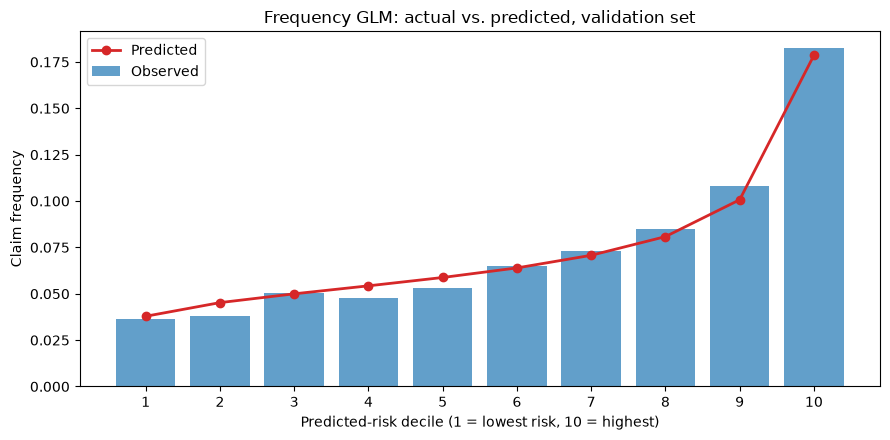

In [10]:
fig = plot_actual_vs_predicted(decile_table, title="Frequency GLM: actual vs. predicted, validation set")
plt.show()

**Reading:** predicted frequency rises monotonically from decile 1 (lowest predicted risk, about
3.8%) to decile 10 (about 17.9%), and observed frequency follows the same order (3.7% to 18.2%). The
model slightly over-predicts in deciles 2 and 4 and slightly under-predicts in deciles 8 and 9, but
ranks policies correctly on data it never saw, which is the check that matters most for a pricing
model.

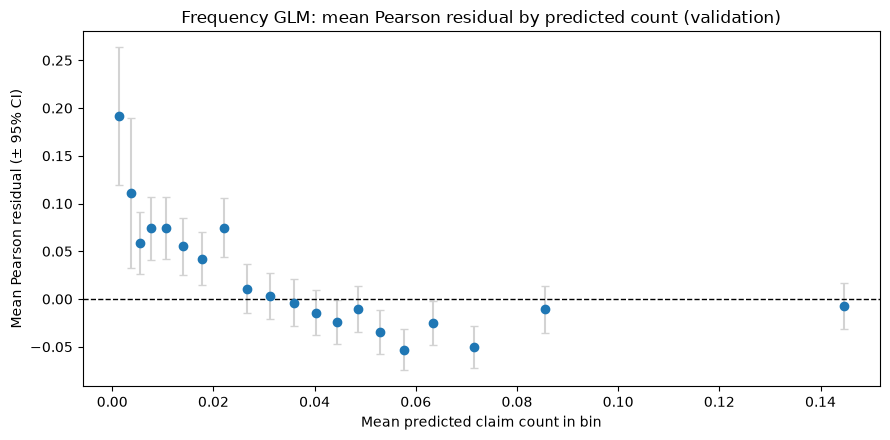

Mean Pearson residual (should be close to 0): 0.0231
Std of Pearson residuals (should be close to 1 for a well-specified Poisson model): 1.4438


In [11]:
residuals_val = pearson_residuals(y_val, predicted_val)
fig = plot_residuals_vs_fitted(predicted_val, residuals_val, title="Frequency GLM: mean Pearson residual by predicted count (validation)")
plt.show()

print(f"Mean Pearson residual (should be close to 0): {residuals_val.mean():.4f}")
print(f"Std of Pearson residuals (should be close to 1 for a well-specified Poisson model): {residuals_val.std():.4f}")

**Reading:** the mean residual is close to zero with no strong systematic trend across the
range of predicted values: no obvious sign of the model being badly miscalibrated at either the
low- or high-risk end. The residual standard deviation sitting somewhat above 1 is a known, expected
feature of motor claim-count data (mild overdispersion relative to a pure Poisson assumption) rather
than a defect specific to this fit: noted here as a limitation for the model card rather than
something this notebook attempts to fix (a Negative Binomial or quasi-Poisson variance adjustment
would be the standard next step, out of scope for this phase).

## 6. Save the model

In [12]:
models_dir = PROJECT_ROOT / "models"
models_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    {
        "results": final_results,
        "feature_columns": final_cols,
        "factor_groups": feature_groups,  # all 8 factors: the specification final_results was fit on (see Section 3's full-data confirmation)
    },
    models_dir / "freq_glm.pkl",
)
print(f"Saved: {(models_dir / 'freq_glm.pkl').relative_to(PROJECT_ROOT).as_posix()}")

Saved: models/freq_glm.pkl


## Phase 4 summary

| Check | Result |
|---|---|
| Full model pseudo-R² (deviance) | 4.1%, normal for a rare-event frequency model |
| Coherence check (`DrivAge` sign) | Explained: negative alone, positive with `BonusMalus` (confounding, r = -0.48) |
| Stepwise selection | Sub-sample search keeps all 8 factors; full-data p-values confirm |
| Relativity directions vs. Phase 2 EDA | Consistent for `BonusMalus`, `VehBrand`, `VehGas`, `Density`, `VehAge` (direction, not full shape) |
| Validation calibration | Predicted frequency ranks correctly across the 10 deciles, on held-out data |
| Known limitation | Mild overdispersion vs. pure Poisson (residual std 1.44), noted, not corrected here |

**Two reasons to build a GAM next (Phase 5):**
1. `DrivAge`'s shape (sharp young-driver drop, then flat) cannot be represented by one linear coefficient.
2. `VehAge`'s hump at 6-7 years is invisible to a linear `VehAge_capped` term.

**Output:** [`models/freq_glm.pkl`](../models/freq_glm.pkl), ready for
**Phase 5: frequency model, GAM and benchmark**.